# Linear Regression - 1

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
!gdown 1bwRmKkPwmLKiqOgQ_LnKH0Vsc3mJKmVR

In [ ]:
!gdown 1bwRmKkPwmLKiqOgQ_LnKH0Vsc3mJKmVR

Downloading...
From: https://drive.google.com/uc?id=1bwRmKkPwmLKiqOgQ_LnKH0Vsc3mJKmVR
To: /content/cars24-car-price-cleaned.csv
100% 1.69M/1.69M [00:00<00:00, 17.4MB/s]


In [ ]:
df = pd.read_csv('cars24-car-price-cleaned.csv')
df.head()

,selling_price,year,km_driven,mileage,engine,max_power,age,make,model,Individual,Trustmark Dealer,Diesel,Electric,LPG,Petrol,Manual,5,>5
0,1.20,2012.0,120000,19.70,796.0,46.30,11.0,MARUTI,ALTO STD,1,0,0,0,0,1,1,1,0
1,5.50,2016.0,20000,18.90,1197.0,82.00,7.0,HYUNDAI,GRAND I10 ASTA,1,0,0,0,0,1,1,1,0
2,2.15,2010.0,60000,17.00,1197.0,80.00,13.0,HYUNDAI,I20 ASTA,1,0,0,0,0,1,1,1,0
3,2.26,2012.0,37000,20.92,998.0,67.10,11.0,MARUTI,ALTO K10 2010-2014 VXI,1,0,0,0,0,1,1,1,0
4,5.70,2015.0,30000,22.77,1498.0,98.59,8.0,FORD,ECOSPORT 2015-2021 1.5 TDCI TITANIUM BSIV,0,0,1,0,0,0,1,1,0


In [ ]:
df.shape

(19820, 18)

In [ ]:
df['make'].nunique(), df['model'].nunique()

(41, 3233)

In [ ]:
#Target encoding
df['make'] = df.groupby('make')['selling_price'].transform('mean')
df['model'] = df.groupby('model')['selling_price'].transform('mean')
df

,selling_price,year,km_driven,mileage,engine,max_power,age,make,model,Individual,Trustmark Dealer,Diesel,Electric,LPG,Petrol,Manual,5,>5
0,1.20,2012.0,120000,19.70,796.0,46.30,11.0,4.684721,1.180000,1,0,0,0,0,1,1,1,0
1,5.50,2016.0,20000,18.90,1197.0,82.00,7.0,5.458819,4.818750,1,0,0,0,0,1,1,1,0
2,2.15,2010.0,60000,17.00,1197.0,80.00,13.0,5.458819,3.394000,1,0,0,0,0,1,1,1,0
3,2.26,2012.0,37000,20.92,998.0,67.10,11.0,4.684721,2.242676,1,0,0,0,0,1,1,1,0
4,5.70,2015.0,30000,22.77,1498.0,98.59,8.0,5.858258,6.777576,0,0,1,0,0,0,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19815,6.50,2017.0,69480,23.59,1364.0,67.05,6.0,10.532763,7.075000,0,0,1,0,0,0,1,1,0
19816,9.25,2019.0,18000,17.50,1373.0,91.10,4.0,4.684721,7.128571,0,0,0,0,0,1,1,0,1
19817,4.25,2015.0,67000,21.14,1498.0,103.52,8.0,7.182097,4.454000,0,0,1,0,0,0,1,1,0
19818,12.25,2016.0,3800000,16.00,2179.0,140.00,7.0,7.315421,8.096522,0,0,1,0,0,0,1,0,1


In [ ]:
#min max scaler
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
df = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)
df

,selling_price,year,km_driven,mileage,engine,max_power,age,make,model,Individual,Trustmark Dealer,Diesel,Electric,LPG,Petrol,Manual,5,>5
0,0.043684,0.689655,0.031553,0.135345,0.117891,0.066506,0.310345,0.194048,0.041550,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0
1,0.252397,0.827586,0.005237,0.128448,0.177281,0.123994,0.172414,0.232517,0.218382,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0
2,0.089795,0.620690,0.015764,0.112069,0.177281,0.120773,0.379310,0.232517,0.149143,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0
3,0.095134,0.689655,0.009711,0.145862,0.147808,0.100000,0.310345,0.194048,0.093193,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0
4,0.262104,0.793103,0.007869,0.161810,0.221860,0.150709,0.206897,0.252367,0.313574,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19815,0.300934,0.862069,0.018258,0.168879,0.202014,0.099919,0.137931,0.484670,0.328028,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
19816,0.434413,0.931034,0.004711,0.116379,0.203347,0.138647,0.068966,0.194048,0.330632,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0
19817,0.191724,0.793103,0.017606,0.147759,0.221860,0.158647,0.206897,0.318156,0.200656,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
19818,0.580027,0.827586,1.000000,0.103448,0.322719,0.217391,0.172414,0.324782,0.377671,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0


In [ ]:
from sklearn.model_selection import train_test_split
y = df['selling_price']
X = df.drop('selling_price', axis=1)

In [ ]:
X.shape, y.shape

((19820, 17), (19820,))

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [ ]:
X_train.shape, X_test.shape

((15856, 17), (3964, 17))

In [ ]:
# Univariate Linear regression [implementation]

from sklearn.linear_model import LinearRegression

In [ ]:
X1_train = X_train[['model']]
X1_test = X_test[['model']]

In [ ]:
model = LinearRegression()
model.fit(X1_train, y_train) # training the model

LinearRegression()

In [ ]:
model.coef_

array([0.99811371])

In [ ]:
model.intercept_

0.0013897655746198945

In [ ]:
# y^ = 0.998x + 0.0013

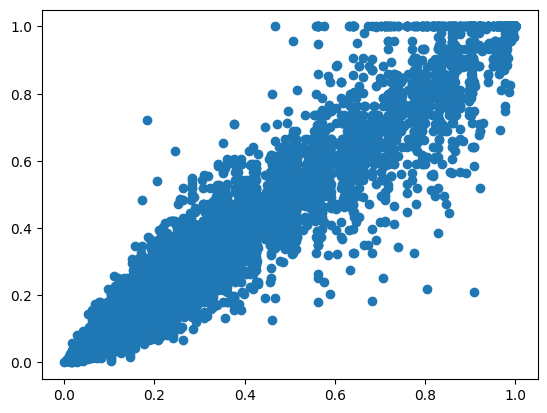

In [ ]:
plt.scatter(X1_train, y_train)
plt.show()

In [ ]:
y_pred_train = model.predict(X1_train)

In [ ]:
X1_train, y_train

(          model
 5662   0.167659
 4556   0.515065
 7094   0.318691
 1441   0.256955
 17079  0.122249
 ...         ...
 11284  0.112800
 11964  0.191210
 5390   0.192868
 860    0.356532
 15795  0.232397
 
 [15856 rows x 1 columns],
 5662     0.240262
 4556     0.385876
 7094     0.349472
 1441     0.262104
 17079    0.179590
            ...   
 11284    0.131052
 11964    0.220847
 5390     0.242689
 860      0.325203
 15795    0.276665
 Name: selling_price, Length: 15856, dtype: float64)

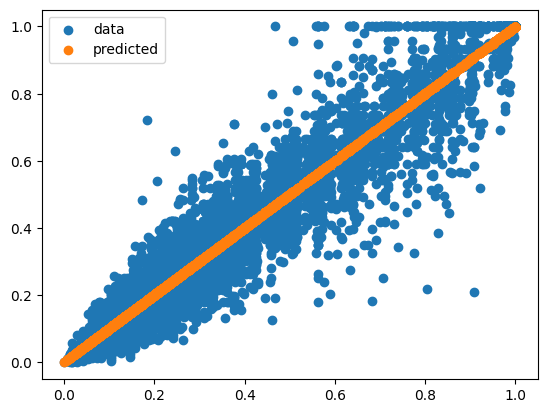

In [ ]:
plt.scatter(X1_train, y_train, label='data')
plt.scatter(X1_train, y_pred_train, label='predicted')
plt.legend()
plt.show()

In [ ]:
# Multi variate

X_train.shape, y_train.shape

((15856, 17), (15856,))

In [ ]:
model2 = LinearRegression()
model2.fit(X_train, y_train)

LinearRegression()

In [ ]:
model2.coef_

array([ 7.00922401e+11, -5.86975098e-01, -2.48301696e-01,  8.67998957e-02,
        3.29948330e-02,  7.00922401e+11,  6.77679855e-02,  8.57520623e-01,
       -5.91190052e-03, -8.06020858e-03,  5.86439883e-03,  1.23974745e-01,
        1.49361302e-02, -1.01023617e-02, -4.40577142e-03, -1.24788372e-02,
       -2.03562239e-02])

In [ ]:
model2.intercept_

-700922400770.2532

In [ ]:
model2.score(X_train, y_train)

0.9454967443849421

# Linear Regression -2

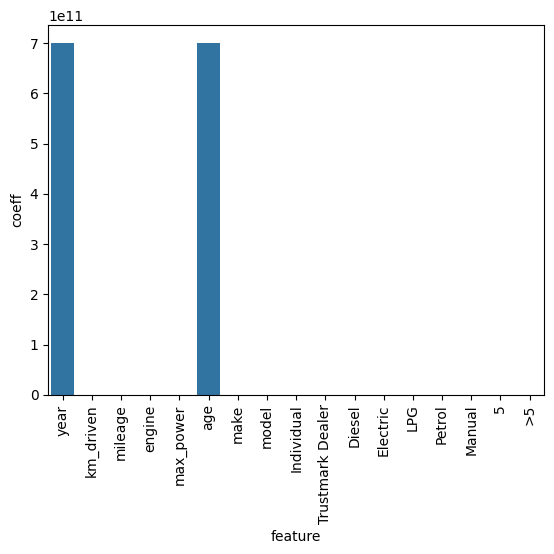

In [ ]:
imp = pd.DataFrame(list(zip(X_test.columns,np.abs(model2.coef_))),
                   columns=['feature', 'coeff'])
sns.barplot(x='feature', y='coeff', data=imp)
plt.xticks(rotation=90)
plt.show()

In [ ]:
def predict(X, weights):
  return np.dot(X, weights)

def loss(X, y, weights):
  yp = predict(X, weights)
  e = np.mean((y-yp)**2)
  return e

def gradient(X, y, weights):
  yp = predict(X, weights)
  grad = np.dot(X.T, (yp-y))
  return 2*grad/len(y)


# Homework
def fit(X, y, learning_rate=0.01, max_iters=100):

  # gradient descent algorithm
  # 1. intiialization
  # gradient
  # update wj = wj-learning_rate*gradient
  d = X.shape[1]
  weights = np.zeros((d,)) # intiailization
  error_list = []

  for i in range(max_iters):
    e = loss(X, y, weights)
    error_list.append(e)
    grad = gradient(X, y, weights)
    weights = weights - learning_rate*grad
  return weights, error_list

def score(X, y, weights):
  yp = predict(X, weights)
  num = np.sum((y-yp)**2)
  denom = np.sum((y-y.mean())**2)
  return 1 - (num/denom)

In [ ]:
weights, error_list = fit(X_train, y_train)

In [ ]:
weights

array([ 0.11338802,  0.00110049,  0.01105461,  0.04669304,  0.04111352,
        0.01022506,  0.08951153,  0.12695209,  0.00082253,  0.00091101,
        0.10434776,  0.00023396, -0.00053663,  0.01943044, -0.00285012,
        0.06558324,  0.05203411])

In [ ]:
error_list[:10]

[0.14782125645625577,
 0.13759782572253074,
 0.12849826916478993,
 0.12039351500878585,
 0.11316938755060081,
 0.106724886833192,
 0.10097066702258185,
 0.09582769053316902,
 0.0912260376025121,
 0.08710385336062981]

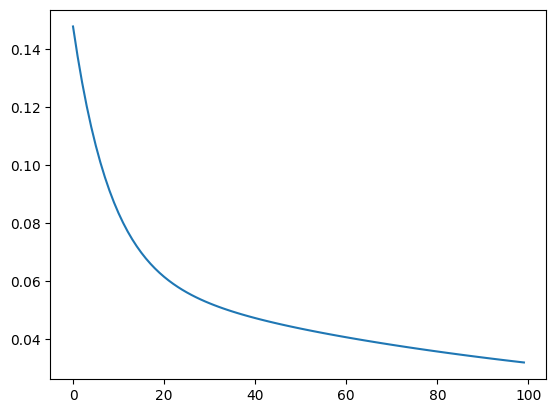

In [ ]:
plt.plot(error_list)
plt.show()

In [ ]:
weights, error_list = fit(X_train, y_train, learning_rate=0.2, max_iters=300)

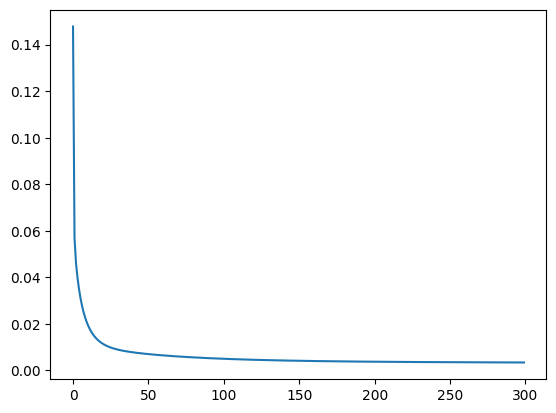

In [ ]:
plt.plot(error_list)
plt.show()

In [ ]:
score(X_train, y_train, weights)

0.9386260476849568

In [ ]:
score(X_test, y_test, weights)

0.9429745081413387

In [ ]:
r2 = score(X_test, y_test, weights)
r2

0.9429745081413387

In [ ]:
n, d = X_test.shape
adj_r2 = (1 - (((1-r2)*(n-1))/(n-d-1-500)))
adj_r2

0.9344190295310868

In [ ]:
import statsmodels.api as sm

X_sm = sm.add_constant(X_train)
model = sm.OLS(y_train, X_sm)
results = model.fit()
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:          selling_price   R-squared:                       0.945
Model:                            OLS   Adj. R-squared:                  0.945
Method:                 Least Squares   F-statistic:                 1.715e+04
Date:                Sat, 28 Sep 2024   Prob (F-statistic):               0.00
Time:                        15:18:06   Log-Likelihood:                 23560.
No. Observations:               15856   AIC:                        -4.709e+04
Df Residuals:                   15839   BIC:                        -4.696e+04
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const             -3.81e+11   8.94e+10  

# Linear Regression - 4

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [ ]:
vif = pd.DataFrame()
X_t = pd.DataFrame(X_train, columns=X_train.columns)
vif['Features'] = X_t.columns
vif['VIF'] = [variance_inflation_factor(X_t.values, i) for i in range(X_t.shape[1])]
vif = vif.sort_values(by='VIF', ascending=False)
vif

,Features,VIF
0,year,206.905284
5,age,20.690332
13,Petrol,16.791890
10,Diesel,15.868120
16,>5,13.319542
15,5,12.113110
3,engine,6.332836
7,model,6.142811
4,max_power,5.110233
6,make,3.257093


In [ ]:
cols2 = vif['Features'][1:].values
X2 = pd.DataFrame(X_train, columns=cols2)
X2_sm = sm.add_constant(X2)
sm_model = sm.OLS(list(y_train), X2_sm).fit()
print(sm_model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.945
Model:                            OLS   Adj. R-squared:                  0.945
Method:                 Least Squares   F-statistic:                 1.713e+04
Date:                Sat, 28 Sep 2024   Prob (F-statistic):               0.00
Time:                        16:46:56   Log-Likelihood:                 23550.
No. Observations:               15856   AIC:                        -4.707e+04
Df Residuals:                   15839   BIC:                        -4.694e+04
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                0.1179      0.008  

In [ ]:
X_t.drop(columns=['year'], inplace=True)
vif = pd.DataFrame()

vif['Features'] = X_t.columns
vif['VIF'] = [variance_inflation_factor(X_t.values, i) for i in range(X_t.shape[1])]
vif = vif.sort_values(by='VIF', ascending=False)
vif

,Features,VIF
14,5,50.934199
2,engine,50.532757
3,max_power,27.365174
9,Diesel,26.812645
12,Petrol,22.469770
1,mileage,22.440674
6,model,16.736415
5,make,11.561622
15,>5,10.887829
13,Manual,8.810880


In [ ]:
X_t.drop(columns=['5'], inplace=True)
vif = pd.DataFrame()

vif['Features'] = X_t.columns
vif['VIF'] = [variance_inflation_factor(X_t.values, i) for i in range(X_t.shape[1])]
vif = vif.sort_values(by='VIF', ascending=False)
vif

,Features,VIF
2,engine,47.502689
3,max_power,27.094447
9,Diesel,23.349754
12,Petrol,16.865796
1,mileage,16.538773
6,model,16.519664
5,make,11.559605
4,age,8.631418
13,Manual,8.610116
0,km_driven,3.632533


In [ ]:
X_t.drop(columns=['engine'], inplace=True)
vif = pd.DataFrame()

vif['Features'] = X_t.columns
vif['VIF'] = [variance_inflation_factor(X_t.values, i) for i in range(X_t.shape[1])]
vif = vif.sort_values(by='VIF', ascending=False)
vif

,Features,VIF
8,Diesel,20.408153
2,max_power,17.020653
5,model,16.354423
1,mileage,16.216073
11,Petrol,15.318046
4,make,11.433575
12,Manual,8.370365
3,age,8.272204
0,km_driven,3.573583
6,Individual,1.787436


In [ ]:
model = LinearRegression()
model.fit(X_t, y_train)

LinearRegression()

In [ ]:
model.score(X_t, y_train)

0.9452019544836632

In [ ]:
#Normality of residuals

In [ ]:
y_hat = model.predict(X_t)

In [ ]:
errs = y_train - y_hat
errs[:5]

,selling_price
5662,0.068825
4556,-0.128409
7094,0.029748
1441,-0.012216
17079,0.089513


<Axes: xlabel='selling_price', ylabel='Count'>

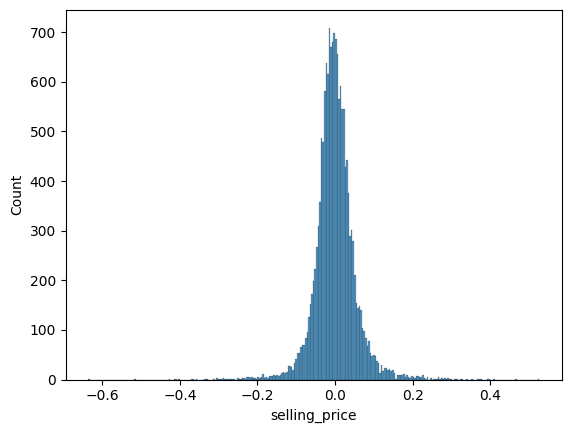

In [ ]:
sns.histplot(errs)

In [ ]:
from scipy import stats
res = stats.shapiro(errs)
res.statistic

/usr/local/lib/python3.10/dist-packages/scipy/stats/_axis_nan_policy.py:531: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 15856.
  res = hypotest_fun_out(*samples, **kwds)


0.8992286444631902

In [ ]:
#Hetroskedasticity

<Axes: ylabel='selling_price'>

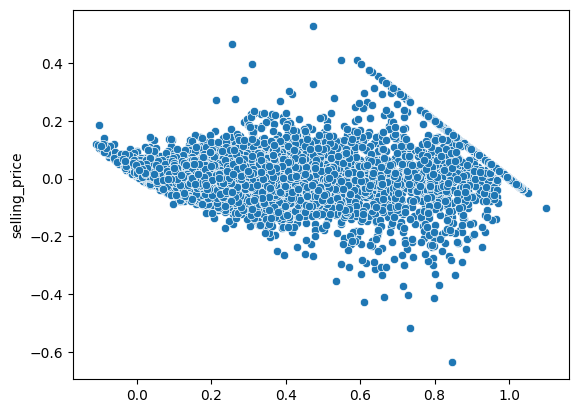

In [ ]:
sns.scatterplot(x=y_hat, y=errs)